<a href="https://colab.research.google.com/github/kylevalibia/IDX-Exchange-Data-Science/blob/main/02_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02.) Data Preprocessing

In [ ]:
# Read data from Google Drive
from google.colab import drive
drive.mount('/content/drive')
path = "/content/drive/MyDrive/Projects/IDX Exchange Data/"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
pd.set_option('display.max_columns', 85)

# Data comes from Notebook 1, contains all data deduplicated and to the scope of the project
all_data = pd.read_csv(path + "unique_raw_scope_data.csv", low_memory=False)
display(all_data.head(5))
print(all_data.shape)

,BuyerAgentAOR,ListAgentAOR,Flooring,ViewYN,WaterfrontYN,BasementYN,PoolPrivateYN,OriginalListPrice,ListingKey,ListAgentEmail,CloseDate,ClosePrice,ListAgentFirstName,ListAgentLastName,Latitude,Longitude,UnparsedAddress,PropertyType,LivingArea,ListPrice,DaysOnMarket,ListOfficeName,BuyerOfficeName,CoListOfficeName,ListAgentFullName,CoListAgentFirstName,CoListAgentLastName,BuyerAgentMlsId,BuyerAgentFirstName,BuyerAgentLastName,FireplacesTotal,AssociationFeeFrequency,AboveGradeFinishedArea,ListingKeyNumeric,MLSAreaMajor,TaxAnnualAmount,CountyOrParish,MlsStatus,ElementarySchool,AttachedGarageYN,ParkingTotal,BuilderName,PropertySubType,LotSizeAcres,SubdivisionName,BuyerOfficeAOR,YearBuilt,StreetNumberNumeric,ListingId,BathroomsTotalInteger,City,TaxYear,BuildingAreaTotal,BedroomsTotal,ContractStatusChangeDate,ElementarySchoolDistrict,CoBuyerAgentFirstName,PurchaseContractDate,ListingContractDate,BelowGradeFinishedArea,BusinessType,StateOrProvince,CoveredSpaces,MiddleOrJuniorSchool,FireplaceYN,Stories,HighSchool,Levels,LotSizeDimensions,LotSizeArea,MainLevelBedrooms,NewConstructionYN,GarageSpaces,HighSchoolDistrict,PostalCode,AssociationFee,LotSizeSquareFeet,MiddleOrJuniorSchoolDistrict,dataset,OriginatingSystemName,OriginatingSystemSubName
0,SanDiego,SanDiego,NaN,False,NaN,NaN,False,880000.0,497696903,lenskab@gmail.com,2025-02-11,875000.0,Lenska,Bracknell,32.765380,-117.043486,4750 Dana Dr,Residential,2340.0,880000.0,20,LENSKA Realty,Coldwell Banker West,NaN,Lenska Bracknell,NaN,NaN,809976,Sheetal,Gandhi,NaN,NaN,NaN,497696903,91942 - La Mesa,NaN,San Diego,Closed,NaN,True,6.0,NaN,SingleFamilyResidence,NaN,La Mesa,PacificSouthwest,2021.0,4750.0,210000201,4.0,La Mesa,NaN,NaN,4.0,2025-02-11,NaN,NaN,2021-01-25,2021-01-05,NaN,NaN,CA,NaN,NaN,False,1.0,NaN,One,NaN,NaN,NaN,False,2.0,NaN,91942,NaN,NaN,NaN,CRMLSSold202502.csv,NaN,NaN
1,SanDiego,SanDiego,NaN,False,NaN,NaN,False,875000.0,497696407,lenskab@gmail.com,2025-02-14,875000.0,Lenska,Bracknell,32.765038,-117.043568,4740 Dana Dr,Residential,2165.0,875000.0,9,LENSKA Realty,LENSKA Realty,NaN,Lenska Bracknell,NaN,NaN,SAND-649841,Lenska,Bracknell,NaN,NaN,NaN,497696407,91942 - La Mesa,NaN,San Diego,Closed,NaN,True,4.0,NaN,SingleFamilyResidence,NaN,La Mesa,SanDiego,2021.0,4740.0,210000200,4.0,La Mesa,NaN,NaN,5.0,2025-02-14,NaN,NaN,2021-01-14,2021-01-05,NaN,NaN,CA,NaN,NaN,False,1.0,NaN,One,NaN,NaN,NaN,False,2.0,NaN,91942,NaN,NaN,NaN,CRMLSSold202502.csv,NaN,NaN
2,SanDiego,SanDiego,NaN,False,NaN,NaN,False,849000.0,486616176,lenskab@gmail.com,2025-02-18,849000.0,Lenska,Bracknell,32.765031,-117.043252,4730 Dana Dr,Residential,2158.0,849000.0,91,LENSKA Realty,Heritage Homes San Diego,NaN,Lenska Bracknell,NaN,NaN,SAND-693007,Jason,Piske,NaN,NaN,NaN,486616176,91942 - La Mesa,NaN,San Diego,Closed,NaN,True,4.0,NaN,SingleFamilyResidence,NaN,La Mesa,SanDiego,2021.0,4730.0,200049530,3.0,La Mesa,NaN,NaN,4.0,2025-02-18,NaN,NaN,2021-01-25,2020-10-22,NaN,NaN,CA,NaN,NaN,False,1.0,NaN,One,NaN,NaN,NaN,False,2.0,NaN,91942,NaN,NaN,NaN,CRMLSSold202502.csv,NaN,NaN
3,SouthBay,SouthBay,Carpet,True,NaN,True,False,1100000.0,1108119618,elaine@elainemallon.com,2025-02-28,1100000.0,Elaine,Mallon,33.724000,-118.294924,2211 S Cabrillo Avenue,Residential,2545.0,1100000.0,0,Rodeo Realty,Rodeo Realty,NaN,Elaine Mallon,NaN,NaN,sbmallela,Elaine,Mallon,NaN,NaN,NaN,1108119618,183 - Vista Del Oro,NaN,Los Angeles,Closed,NaN,False,3.0,NaN,SingleFamilyResidence,0.1033,NaN,SouthBay,1962.0,2211.0,SB24235361,3.0,San Pedro,NaN,NaN,4.0,2025-02-28,NaN,NaN,2025-01-10,2024-11-18,NaN,NaN,CA,NaN,NaN,True,2.0,San Pedro,Two,NaN,4501.0,4.0,False,2.0,Los Angeles Unified,90731,0.0,4501.0,NaN,CRMLSSold202502.csv,NaN,NaN
4,ContraCosta,ContraCosta,Carpet,NaN,NaN,NaN,False,760000.0,1108119338,sabine.larsen@redfin.com,2025-02-28,760000.0,Sabine,Larsen,37.687556,-122.150114,15216 Edgemoor St,Residential,1692.0,760000.0,0,Redfin,Legacy Real Estate & Assoc.,NaN,Sabine Larsen,NaN,NaN,CCBE-206516251,Kristy,Peixoto,NaN,NaN,NaN,1108119338,NaN,NaN,Alameda,Closed,NaN

(162454, 81)


In [ ]:
# Selecting key columns that may be important in our analysis, change if need be
key_columns = ['ListingKey',
               'CloseDate',
               'ClosePrice',
               'Latitude',
               'Longitude',
               'UnparsedAddress',
               'LivingArea',
               'ListPrice',
               'YearBuilt',
               'BathroomsTotalInteger',
               'City',
               'BedroomsTotal',
               'LotSizeSquareFeet',
               'dataset',
               'ListingContractDate']

key_data = all_data[key_columns]

key_data["Latitude"].astype(float)
key_data["Longitude"].astype(float)

display(key_data.head(5))
print(key_data.shape)

,ListingKey,CloseDate,ClosePrice,Latitude,Longitude,UnparsedAddress,LivingArea,ListPrice,YearBuilt,BathroomsTotalInteger,City,BedroomsTotal,LotSizeSquareFeet,dataset,ListingContractDate
0,497696903,2025-02-11,875000.0,32.765380,-117.043486,4750 Dana Dr,2340.0,880000.0,2021.0,4.0,La Mesa,4.0,NaN,CRMLSSold202502.csv,2021-01-05
1,497696407,2025-02-14,875000.0,32.765038,-117.043568,4740 Dana Dr,2165.0,875000.0,2021.0,4.0,La Mesa,5.0,NaN,CRMLSSold202502.csv,2021-01-05
2,486616176,2025-02-18,849000.0,32.765031,-117.043252,4730 Dana Dr,2158.0,849000.0,2021.0,3.0,La Mesa,4.0,NaN,CRMLSSold202502.csv,2020-10-22
3,1108119618,2025-02-28,1100000.0,33.724000,-118.294924,2211 S Cabrillo Avenue,2545.0,1100000.0,1962.0,3.0,San Pedro,4.0,4501.0,CRMLSSold202502.csv,2024-11-18
4,1108119338,2025-02-28,760000.0,37.687556,-122.150114,15216 Edgemoor St,1692.0,760000.0,1950.0,2.0,San Leandro,4.0,5040.0,CRMLSSold202502.csv,2025-02-28


(162454, 15)


---
---

# Creating Time-Based Test/Train Split

Before doing some imputation, encoding, and normalization of features, let's first deal with the outliers in our dataset and create our test/training split to prevent data leakage.

* Our test split will be the months 2026/03 - 2026/04.
* Our training split will be the months 2025/02 - 2026/02.

Notice that we have some impossible outliers (i.e. 0 LivingArea, 0 Bathrooms). After some short investigation into these entries, entries with 0's of multiple values were common (LivingArea = 0) which signals an error when creating this dataset.\
\
Since all of these strange values amounted to only 1.2% (including bounding `ClosePrice > 1000` and `LivingArea > 150`, as well as a `CloseDate` preceding a `ListingContractDate`), we can drop these values since we still retain a large portion of our data.

In [ ]:
pre_count = len(key_data)
key_data.drop(['ListingKey', 'Latitude', 'Longitude', 'YearBuilt'], axis=1).describe().T.style.format(precision=3)

,count,mean,std,min,25%,50%,75%,max
ClosePrice,162454.000,1330773.427,7601264.346,0.000,625000.000,890000.000,1423791.750,989500000.000
LivingArea,162367.000,2045.132,1039.034,0.000,1384.000,1816.000,2437.000,56500.000
ListPrice,162454.000,1265024.708,1591761.987,8000.000,625000.000,893845.000,1399800.000,137500000.000
BathroomsTotalInteger,162435.000,2.630,1.136,0.000,2.000,2.000,3.000,45.000
BedroomsTotal,162454.000,3.488,0.971,0.000,3.000,3.000,4.000,45.000
LotSizeSquareFeet,159623.000,358987.345,17731021.636,0.000,5663.000,7280.000,10454.000,2087220960.000


In [ ]:
key_data = key_data.copy()
key_data['CloseDate'] = pd.to_datetime(key_data['CloseDate'], errors='coerce')
key_data['SaleYear'] = key_data['CloseDate'].dt.year
key_data['AgeAtSale'] = key_data['SaleYear']- key_data['YearBuilt']

In [ ]:
print(f"All data entries before initial cleaning: {pre_count}")
key_data = key_data.copy()

# Illogical/strange values removed to preserve data quality
key_data = key_data.loc[key_data["ClosePrice"] > 1000]
key_data = key_data.loc[key_data["BedroomsTotal"] > 0]
key_data = key_data.loc[key_data["BathroomsTotalInteger"] > 0]
key_data = key_data.loc[key_data["LivingArea"] > 150]
key_data = key_data[key_data["CloseDate"] > key_data["ListingContractDate"]]

# Setting illogical values to NaN
# LotSizeSquareFeet <= 0 set to NaN
# Latitude/Longitude values not in bound to California region set to NaN
key_data = key_data.copy()
key_data.loc[key_data['LotSizeSquareFeet'] <= 0, 'LotSizeSquareFeet'] = np.nan

bad_lat = key_data['Latitude'].notna() & ~key_data['Latitude'].between(32, 43)
bad_lon = key_data['Longitude'].notna() & ~key_data['Longitude'].between(-125, -113)

key_data.loc[bad_lat | bad_lon, ['Latitude', 'Longitude']] = np.nan

# These two columns contain No City and No Latitude/Longitude, but an address. After looking up the address,
# these homes are not located in California. They'll be removed from the dataset.

invalid_indices = key_data.index[(key_data["City"].isna() == True) & (key_data["Latitude"].isna() == True)].tolist()
key_data = key_data.drop(invalid_indices)

# Create a new column `AgeAtSale`
key_data['CloseDate'] = pd.to_datetime(key_data['CloseDate'], errors='coerce')
key_data['SaleYear'] = key_data['CloseDate'].dt.year
key_data['AgeAtSale'] = key_data['SaleYear']- key_data['YearBuilt']

print(f"All data entries after initial cleaning: {len(key_data)}")
print(f"Percentage removed: {round((((pre_count - len(key_data)) / pre_count) * 100), 5)}%")
print("")

# Create a new column `logLivingArea`
key_data['logLivingArea'] = np.log1p(key_data["LivingArea"])

# Create a new column `logLotSizeSquareFeet
key_data['logLotSizeSquareFeet'] = np.log1p(key_data["LotSizeSquareFeet"])

# Create a new column `LotSizeSqFt_missing`
key_data['LotSize_missing'] = key_data['LotSizeSquareFeet'].isna().astype(int)
key_data.head(5)

All data entries before initial cleaning: 162454
All data entries after initial cleaning: 160493
Percentage removed: 1.20711%



,ListingKey,CloseDate,ClosePrice,Latitude,Longitude,UnparsedAddress,LivingArea,ListPrice,YearBuilt,BathroomsTotalInteger,City,BedroomsTotal,LotSizeSquareFeet,dataset,ListingContractDate,SaleYear,AgeAtSale,logLivingArea,logLotSizeSquareFeet,LotSize_missing
0,497696903,2025-02-11,875000.0,32.765380,-117.043486,4750 Dana Dr,2340.0,880000.0,2021.0,4.0,La Mesa,4.0,NaN,CRMLSSold202502.csv,2021-01-05,2025,4.0,7.758333,NaN,1
1,497696407,2025-02-14,875000.0,32.765038,-117.043568,4740 Dana Dr,2165.0,875000.0,2021.0,4.0,La Mesa,5.0,NaN,CRMLSSold202502.csv,2021-01-05,2025,4.0,7.680637,NaN,1
2,486616176,2025-02-18,849000.0,32.765031,-117.043252,4730 Dana Dr,2158.0,849000.0,2021.0,3.0,La Mesa,4.0,NaN,CRMLSSold202502.csv,2020-10-22,2025,4.0,7.677400,NaN,1
3,1108119618,2025-02-28,1100000.0,33.724000,-118.294924,2211 S Cabrillo Avenue,2545.0,1100000.0,1962.0,3.0,San Pedro,4.0,4501.0,CRMLSSold202502.csv,2024-11-18,2025,63.0,7.842279,8.412277,0
6,1108118071,2025-02-26,4750000.0,33.637536,-117.895599,1736 Marlin Way,3746.0,4750000.0,1959.0,5.0,Newport Beach,6.0,15200.0,CRMLSSold202502.csv,2024-12-20,2025,66.0,8.228711,9.629116,0


In [ ]:
# Create Test/Train Split
# 2026/03 - 2026/04 TEST
# 2025/02 - 2026/02 TRAIN
training_dates = pd.period_range("202502", "202602", freq="M").astype(str).str.replace("-", "", regex=False)
test_dates = pd.period_range("202603", "202604", freq="M").astype(str).str.replace("-", "", regex=False)

training_data = pd.DataFrame()
test_data = pd.DataFrame()

def select_dates(df, dates):
  temp_df = df
  for date in dates:
    temp = key_data[key_data['dataset'] == "CRMLSSold" + date + ".csv"]
    temp_df = pd.concat([temp_df, temp])
  df = temp_df
  return df

test_data = select_dates(test_data, test_dates).drop(columns=["ListingContractDate"])
training_data = select_dates(training_data, training_dates).drop(columns=["ListingContractDate"])

print(f"Entries in Test Data: {len(test_data)}")
print(f"Entries in Training Data: {len(training_data)}")

Entries in Test Data: 23724
Entries in Training Data: 136769


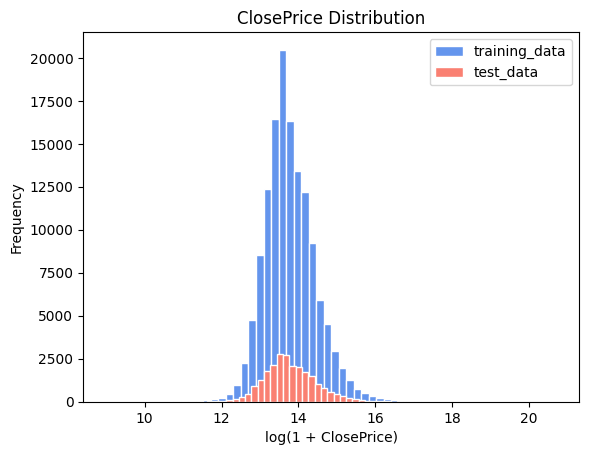

In [ ]:
test_train_counts = pd.DataFrame({"TrainingDataCounts" : [len(training_data)],
                                  "TestDataCounts" : [len(test_data)]
                                  })
np.log1p(training_data["ClosePrice"]).plot(kind='hist', bins=60, edgecolor="white", color='cornflowerblue')
np.log1p(test_data["ClosePrice"]).plot(kind='hist', bins=60, edgecolor="white", color='salmon')
plt.xlabel("log(1 + ClosePrice)")
plt.title("ClosePrice Distribution")
plt.legend(["training_data", 'test_data']);


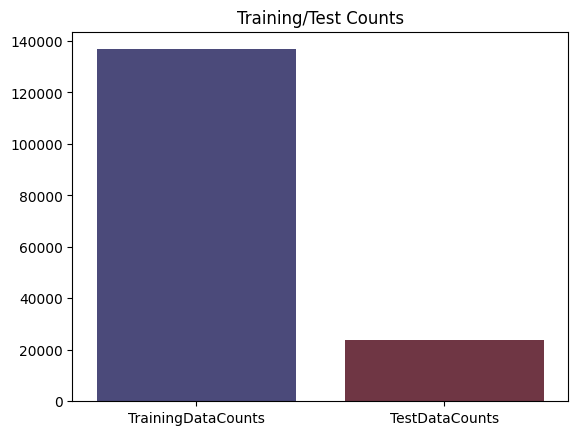

In [ ]:
sns.barplot(data = test_train_counts, palette='icefire')
plt.title("Training/Test Counts");

---
---

# Handle Missing Values

Decide if we want to use deletion methods or imputation methods. Additionally, take a look at outliers and determine if removal is necessary.

We'll focus on the `training_data`.

First we'll remove outliers from `training_data` based off of `ClosePrice`. We'll create upper and lower bounds using the 0.5th quartile and the 99.5th quartile based on the `training_data`.

In [ ]:
pre_train_count = len(training_data)

In [ ]:
upper_bounds = training_data["ClosePrice"].quantile(0.995)
lower_bounds = training_data["ClosePrice"].quantile(0.005)

print(f"Entries of training_data before applying bounds: {pre_train_count}")
training_data = training_data[training_data["ClosePrice"].between(lower_bounds, upper_bounds)].copy()
print(f"Entries of training_data after applying bounds: {len(training_data)}")
print(f"Percentage removed: {round(((pre_train_count - len(training_data))/pre_train_count) * 100, 5)}%")

Entries of training_data before applying bounds: 136769
Entries of training_data after applying bounds: 135408
Percentage removed: 0.99511%


,index,missing_counts,missingness_proportion
1,LotSizeSquareFeet,2418,0.017857
2,UnparsedAddress,115,0.000849
3,Longitude,93,0.000687
4,Latitude,93,0.000687
5,City,57,0.000421
6,AgeAtSale,57,0.000421
7,YearBuilt,57,0.000421
8,ClosePrice,0,0.000000
9,ListingKey,0,0.000000
10,CloseDate,0,0.000000


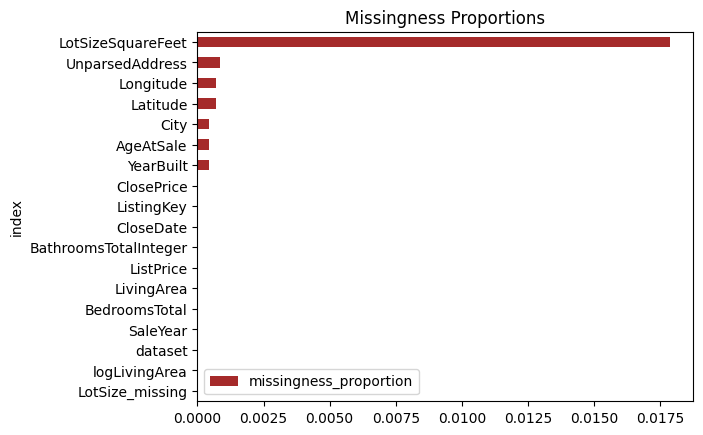

In [ ]:
# Counts all missing values for each key column
def missing_barchart(df):
  missing_values = df.isna().sum().sort_values(ascending=False).reset_index().drop(index=0)
  missing_values = missing_values.rename(columns={0 : 'missing_counts'})
  missing_values["missingness_proportion"] = missing_values["missing_counts"] / len(df)
  display(missing_values)
  missing_values.plot(kind='barh', x="index", y="missingness_proportion", color = 'brown').invert_yaxis()
  plt.title("Missingness Proportions");

missing_barchart(training_data)

Let's deal with `LotSizeSquareFeet`. \
\
What we'll do to fix missing lot sizes is aggregating the median by `City`. Then, we will find the median by using the overall median of `LotSizeSquareFeet`.\
\
**NOTE**: we must use bins fitted to the training_data set and apply to the test_set *without* touching the bins.


In [ ]:
# We can impute LotSizeSquareFeet with the median using the City
# Fit on training_data only, before any imputation
city_medians = training_data.groupby('City')['LotSizeSquareFeet'].median()
global_median = training_data['LotSizeSquareFeet'].median()

def impute_lotsize(df):
    df = df.copy()
    df['LotSizeSquareFeet'] = (
        df['LotSizeSquareFeet']
        .fillna(df['City'].map(city_medians))
        .fillna(global_median)
    )
    return df

training_data = impute_lotsize(training_data)
print(f"Remaining NaN LotSizeSquareFeet values: {training_data["LotSizeSquareFeet"].isna().sum()}")

Remaining NaN LotSizeSquareFeet values: 0


,index,missing_counts,missingness_proportion
1,UnparsedAddress,115,0.000849
2,Longitude,93,0.000687
3,Latitude,93,0.000687
4,City,57,0.000421
5,AgeAtSale,57,0.000421
6,YearBuilt,57,0.000421
7,ClosePrice,0,0.000000
8,CloseDate,0,0.000000
9,ListingKey,0,0.000000
10,LivingArea,0,0.000000


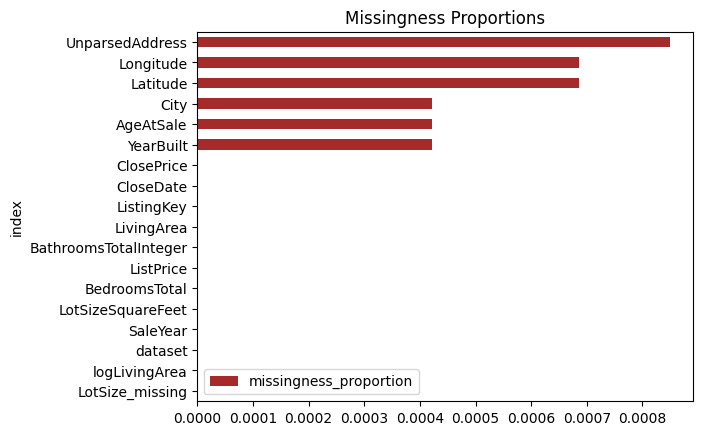

In [ ]:
missing_barchart(training_data)

## What should we do with the rest of the missing values??

Take a look at the numbers:

  * `Latitude` and `Longitude` are all jointed (i.e. NaN lat matches with NaN long) so 93 entries
  * `City` has 57 entries
  * `AgeAtSale` has 57 entries


We are ignoring `UnparsedAddress` and `BuiltYear`.


In [ ]:
df = training_data

total = len(df[df["City"].isna() == True]) + len(df[df["AgeAtSale"].isna() == True]) - len(df[(df['City'].isna() == True) & (df['AgeAtSale'].isna() == True)])
len(df[(df["Latitude"].isna() == True) & (df["AgeAtSale"].isna() == True)])
len(df[(df["Latitude"].isna() == True) & (df["City"].isna() == True)])


0

All entries are disjointed, so our total number of missing columns is 211. This approximates to:

In [ ]:
x = 211 / len(training_data)
x * 100

0.15582535743826068

Around 0.155% of our data that contains missing values! What we could do is impute or reverse geocode some entries in our dataset, but reverse geocode can be expensive and imputing important features such as locations can influence our results in a meaningful way.\
\
Rather than dealing with it, I will be dropping these values in our training data set. Luckily, 0.156% is a trivial amount of entries (211 rows out of 135408)

In [ ]:
training_data.copy()
pre_count = len(training_data)

training_data = training_data.drop(training_data[training_data["Latitude"].isna() == True].index)
training_data = training_data.drop(training_data[training_data["City"].isna() == True].index)
training_data = training_data.drop(training_data[training_data["AgeAtSale"].isna() == True].index)

print(f"# of entries before ANY removals: {pre_train_count}")
print(f"# of entries after FINAL removals: {len(training_data)}")
print(f"Percentage removed: {round(((pre_train_count - len(training_data)) / pre_count), 7) * 100}%")

# of entries before ANY removals: 136769
# of entries after FINAL removals: 135201
Percentage removed: 1.15798%


Let's perform these same actions to our `test_data`, using parameters that come FROM `training_data`. We will take not of missing values at the end and not peek at our data.

In [ ]:
pre_count = len(test_data)

test_data = test_data.copy()
# `training_data` outliers applied to `test_data`
test_data = test_data[test_data["ClosePrice"].between(lower_bounds, upper_bounds)].copy()

# `LotSizeSquareFeet` imputation using `training_data` medians
test_data = impute_lotsize(test_data)

# Removing remaining NaN values
test_data = test_data.drop(test_data[test_data["Latitude"].isna() == True].index)
test_data = test_data.drop(test_data[test_data["City"].isna() == True].index)
test_data = test_data.drop(test_data[test_data["AgeAtSale"].isna() == True].index)



print(f"Percentage removed: {round((((pre_count - len(test_data)) / pre_count) * 100), 5)}%")

Percentage removed: 1.783%


# Convert Categorical Fields to Numeric

The only categorical field that we need to convert to numeric is the `City` column. We can fit on the `training_data` and apply it to both the `training_data` and the `test_data`.

In [ ]:
# Key features I'll be using in analysis
features = ["Latitude",
            "Longitude",
            "City",
            "BedroomsTotal",
            "BathroomsTotalInteger",
            "SaleYear",
            "AgeAtSale",
            "logLivingArea",
            "logLotSizeSquareFeet",
            "LotSize_missing"]

training_data = training_data[features]
test_data = test_data[features]

# Categorical features: City

from sklearn.preprocessing import OneHotEncoder

# Create the encoder and fit on TRAIN only
ohe = OneHotEncoder(
    handle_unknown='infrequent_if_exist',
    min_frequency=20,                      # cities with < 20 train rows get grouped
    sparse_output=False,
)
ohe.fit(training_data[['City']])

# Transform a dataframe into city columns
def encode_city(df):
    city_arr = ohe.transform(df[['City']])
    city_df = pd.DataFrame(city_arr,columns=ohe.get_feature_names_out(['City']),index=df.index,)
    return pd.concat([df.drop(columns='City'), city_df], axis=1)

train_encoded = encode_city(training_data)
test_encoded = encode_city(test_data)

print(train_encoded.shape, test_encoded.shape)
print(list(train_encoded.columns) == list(test_encoded.columns))

(135201, 502) (23301, 502)
True


# Normalize Features

Normalizing our numerical columns!! Final step before we can fit our regression line.

In [ ]:
from sklearn.preprocessing import StandardScaler

numerical_cols = ["Latitude",
                  "Longitude",
                  "logLivingArea",
                  "logLotSizeSquareFeet",
                  "BedroomsTotal",
                  "BathroomsTotalInteger",
                  "AgeAtSale",
                  "SaleYear"]

scaler = StandardScaler()
scaler.fit(train_encoded[numerical_cols])

X_train = train_encoded.copy()
X_test = test_encoded.copy()

# Obtain normalized columns
X_train[numerical_cols] = scaler.transform(train_encoded[numerical_cols])
X_test[numerical_cols] = scaler.transform(test_encoded[numerical_cols])

# Combine all of our final columns to create last training and datasets ready for linear regression
city_cols = [c for c in X_train.columns if c.startswith("City_")]
final_features = numerical_cols + city_cols + ["LotSize_missing"]


X_train = X_train[final_features]
X_test = X_test[final_features]

In [ ]:
display(X_train.shape)
display(X_test.shape)

(135201, 502)

(23301, 502)

In [ ]:
from google.colab import files

X_train.to_csv('x_train.csv', index=False)
X_test.to_csv('x_test.csv', index=False)

files.download('X_train.csv')
files.download('X_test.csv')